# Black-Scholes option pricing: a walk-through

This notebook uses `black_scholes.py` to price European options, plot their Greeks and recover implied volatility.
Every cell runs offline with illustrative parameters; the last section shows how to use live market data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import black_scholes as bs

plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.grid": True,
                     "grid.color": "#e4e3df", "axes.spines.top": False, "axes.spines.right": False})
CALL, PUT = "#2a78d6", "#eb6834"

# An at-the-money option on a 100 stock, 3 months to expiry, 4% rate, 25% volatility
S, K, T, r, sigma = 100.0, 100.0, 0.25, 0.04, 0.25

## 1. Prices and put-call parity

In [2]:
call = bs.price(S, K, T, r, sigma, "call")
put = bs.price(S, K, T, r, sigma, "put")
print(f"Call {call:.4f}   Put {put:.4f}")
print(f"Put-call parity: C - P = {call - put:.4f}, S - K*exp(-rT) = {S - K * np.exp(-r * T):.4f}")

Call 5.4721   Put 4.4771
Put-call parity: C - P = 0.9950, S - K*exp(-rT) = 0.9950


## 2. How the price depends on the spot and on time to expiry

With more time left the option is worth more, and its value curve is smoother; close to expiry it approaches the payoff (the kink at the strike).

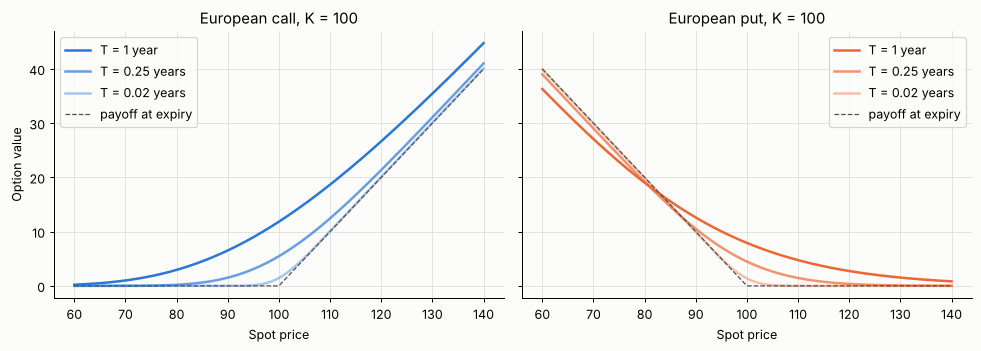

In [3]:
spots = np.linspace(60, 140, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, kind, colour in [(axes[0], "call", CALL), (axes[1], "put", PUT)]:
    for T_i, alpha in [(1.0, 1.0), (0.25, 0.7), (0.02, 0.4)]:
        ax.plot(spots, bs.price(spots, K, T_i, r, sigma, kind), color=colour, alpha=alpha, lw=2,
                label=f"T = {T_i:g} year" + ("" if T_i == 1 else "s"))
    payoff = np.maximum(spots - K, 0) if kind == "call" else np.maximum(K - spots, 0)
    ax.plot(spots, payoff, color="#52514e", ls="--", lw=1, label="payoff at expiry")
    ax.set_title(f"European {kind}, K = {K:g}")
    ax.set_xlabel("Spot price")
    ax.legend()
axes[0].set_ylabel("Option value")
fig.tight_layout()

## 3. The Greeks

Delta is the hedge ratio, gamma how fast delta changes, vega the exposure to volatility and theta the daily time decay.
Gamma and vega are the same for calls and puts and peak near the strike.

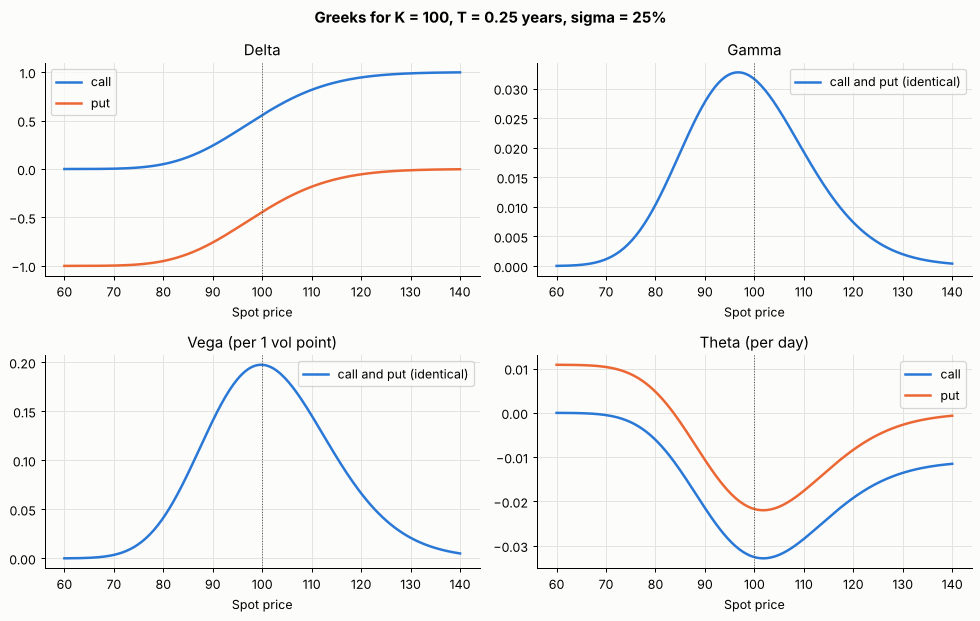

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
panels = [
    ("Delta", lambda k: bs.delta(spots, K, T, r, sigma, k)),
    ("Gamma", lambda k: bs.gamma(spots, K, T, r, sigma)),
    ("Vega (per 1 vol point)", lambda k: bs.vega(spots, K, T, r, sigma) / 100),
    ("Theta (per day)", lambda k: bs.theta(spots, K, T, r, sigma, k) / 365),
]
for ax, (name, f) in zip(axes.flat, panels):
    both = name.startswith(("Delta", "Theta"))
    ax.plot(spots, f("call"), color=CALL, lw=2, label="call" if both else "call and put (identical)")
    if both:
        ax.plot(spots, f("put"), color=PUT, lw=2, label="put")
    ax.axvline(K, color="#52514e", lw=0.8, ls=":")
    ax.set_title(name)
    ax.set_xlabel("Spot price")
    ax.legend()
fig.suptitle(f"Greeks for K = {K:g}, T = {T:g} years, sigma = {sigma:.0%}", fontweight="bold")
fig.tight_layout()

In [5]:
for kind in ("call", "put"):
    print(kind, {name: round(value, 4) for name, value in bs.greeks(S, K, T, r, sigma, kind).items()})

call {'price': 5.4721, 'delta': 0.5567, 'gamma': 0.0316, 'vega_per_vol_point': 0.1975, 'theta_per_day': -0.0325, 'rho_per_rate_point': 0.1255}
put {'price': 4.4771, 'delta': -0.4433, 'gamma': 0.0316, 'vega_per_vol_point': 0.1975, 'theta_per_day': -0.0217, 'rho_per_rate_point': -0.122}


## 4. Implied volatility

Given a market price, find the volatility that makes the model price equal to it. The solver uses Brent's method,
which always converges inside its search range, and refuses prices that break the no-arbitrage bounds.

In [6]:
market_price = 6.50
iv = bs.implied_volatility(market_price, S, K, T, r, "call")
print(f"A call trading at {market_price:.2f} implies a volatility of {iv:.2%}")
print(f"Check: model price at that volatility = {bs.price(S, K, T, r, iv, 'call'):.4f}")

try:
    bs.implied_volatility(120.0, S, K, T, r, "call")
except ValueError as error:
    print("Impossible price rejected:", error)

A call trading at 6.50 implies a volatility of 30.21%
Check: model price at that volatility = 6.5000
Impossible price rejected: Price 120.0000 is outside the no-arbitrage range (0.9950, 100.0000); no implied volatility exists.


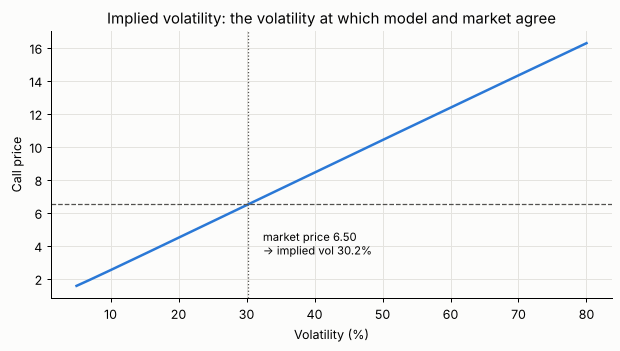

In [7]:
vols = np.linspace(0.05, 0.80, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(vols * 100, bs.price(S, K, T, r, vols, "call"), color=CALL, lw=2)
ax.axhline(market_price, color="#52514e", ls="--", lw=1)
ax.axvline(iv * 100, color="#52514e", ls=":", lw=1)
ax.annotate(f"market price {market_price:.2f}\n-> implied vol {iv:.1%}", (iv * 100, market_price),
            xytext=(12, -40), textcoords="offset points", fontsize=9)
ax.set_xlabel("Volatility (%)")
ax.set_ylabel("Call price")
ax.set_title("Implied volatility: the volatility at which model and market agree")
fig.tight_layout()

## 5. Live data (needs internet)

`price_option.py` downloads a year of prices and an at-the-money option quote with yfinance, then compares the
**implied** volatility with the **historical** one:

```bash
pip install yfinance
python price_option.py AAPL
```

A model price that differs from the market price does not mean the option is cheap or expensive. It means the market
expects a different volatility from the one measured in the past, which is the comparison the script reports.